In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

In [3]:
n = 300

df = pd.DataFrame({
    "channel": np.random.choice(
        ["Social Media", "Search Ads", "Email Marketing", "Display Ads"],
        n
    ),
    "spend": np.random.uniform(100, 5000, n),
    "clicks": np.random.randint(20, 1000, n),
    "conversions": np.random.randint(1, 100, n)
})

# Illustrative revenue factors for each channel
channel_factor = df["channel"].map({
    "Social Media": 2.2,
    "Search Ads": 3.8,
    "Email Marketing": 4.2,
    "Display Ads": 1.4
})

# Generate illustrative revenue
df["revenue"] = (
    df["spend"] *
    channel_factor *
    np.random.uniform(0.7, 1.3, n)
).round(2)

print("Marketing Dataset:")
print(df.head(10))

Marketing Dataset:
           channel        spend  clicks  conversions   revenue
0     Social Media  1541.423069     841           31   2384.43
1     Social Media  4567.996571     404           78  11623.30
2       Search Ads  4840.805192     191           20  13266.27
3  Email Marketing  1008.748486     395           18   4861.41
4      Display Ads  2364.276725     704           93   2719.12
5       Search Ads   106.035992     381           60    513.68
6     Social Media  3031.803599     578           63   6141.47
7     Social Media  3075.801596     910            6   6064.10
8       Search Ads  1312.945782     160           32   3938.13
9  Email Marketing  2836.222096     906           93  10522.73


In [4]:
summary = df.groupby("channel").agg(
    total_spend=("spend", "sum"),
    total_revenue=("revenue", "sum"),
    total_conversions=("conversions", "sum"),
    total_clicks=("clicks", "sum")
).reset_index()

# Calculate Return on Ad Spend (ROAS)
summary["ROAS"] = (
    summary["total_revenue"] / summary["total_spend"]
).round(2)

# Calculate cost per conversion
summary["cost_per_conversion"] = (
    summary["total_spend"] / summary["total_conversions"]
).round(2)

print("Marketing Performance Analysis:")
print(summary.to_string(index=False))

Marketing Performance Analysis:
        channel   total_spend  total_revenue  total_conversions  total_clicks  ROAS  cost_per_conversion
    Display Ads 194180.835783      272218.16               3367         39031  1.40                57.67
Email Marketing 214740.809034      909903.19               3636         39596  4.24                59.06
     Search Ads 152314.256444      584405.08               3391         36478  3.84                44.92
   Social Media 219432.849871      463422.43               3788         40704  2.11                57.93


In [5]:
best_channel = summary.loc[summary["ROAS"].idxmax()]

print("Best Performing Marketing Channel:")
print("Channel:", best_channel["channel"])
print("Total Spend:", round(best_channel["total_spend"], 2))
print("Total Revenue:", round(best_channel["total_revenue"], 2))
print("ROAS:", best_channel["ROAS"])

Best Performing Marketing Channel:
Channel: Email Marketing
Total Spend: 214740.81
Total Revenue: 909903.19
ROAS: 4.24


In [6]:
summary["recommended_budget_share_pct"] = (
    summary["ROAS"] / summary["ROAS"].sum() * 100
).round(2)

print("Recommended Budget Allocation:")
print(
    summary[
        ["channel", "ROAS", "recommended_budget_share_pct"]
    ].sort_values(
        by="recommended_budget_share_pct",
        ascending=False
    ).to_string(index=False)
)

Recommended Budget Allocation:
        channel  ROAS  recommended_budget_share_pct
Email Marketing  4.24                         36.58
     Search Ads  3.84                         33.13
   Social Media  2.11                         18.21
    Display Ads  1.40                         12.08


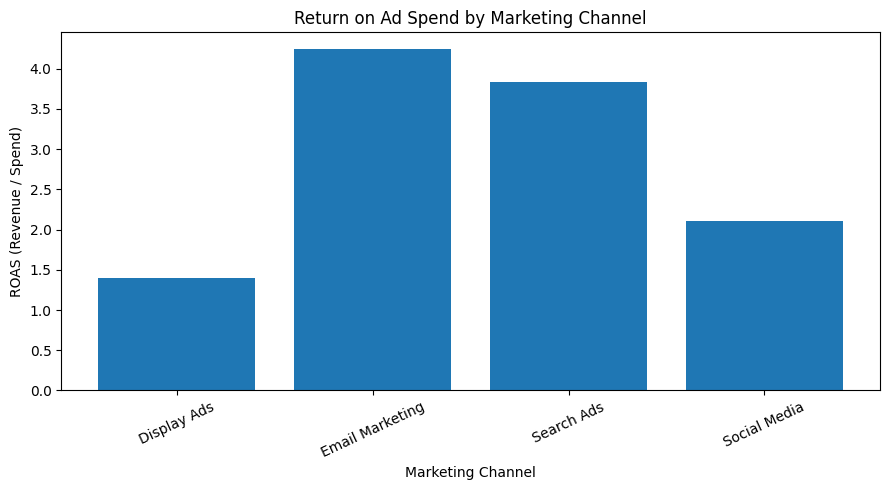

In [7]:
plt.figure(figsize=(9, 5))

plt.bar(summary["channel"], summary["ROAS"])

plt.title("Return on Ad Spend by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("ROAS (Revenue / Spend)")
plt.xticks(rotation=25)
plt.tight_layout()

plt.show()

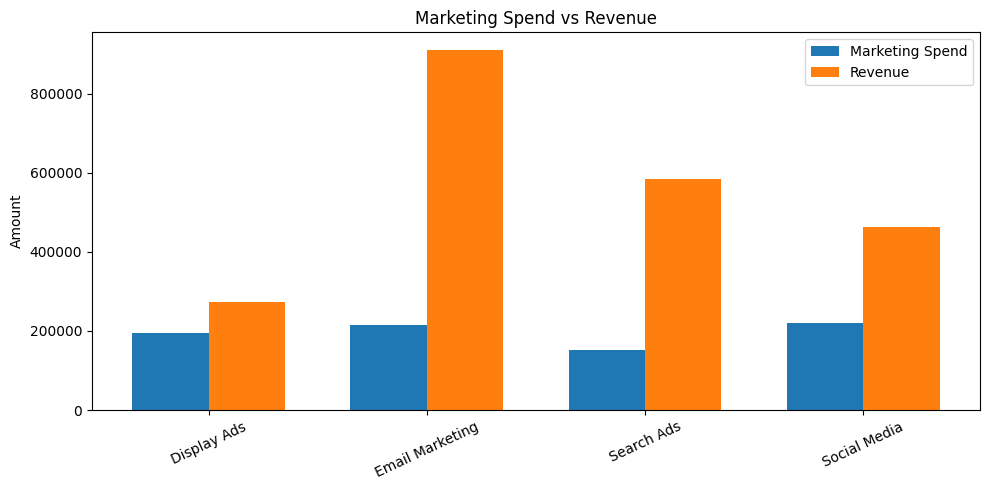

In [9]:
x = np.arange(len(summary))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    summary["total_spend"],
    width,
    label="Marketing Spend"
)

plt.bar(
    x + width / 2,
    summary["total_revenue"],
    width,
    label="Revenue"
)

plt.xticks(x, summary["channel"], rotation=25)
plt.ylabel("Amount")
plt.title("Marketing Spend vs Revenue")
plt.legend()
plt.tight_layout()

plt.show()

In [10]:
print("BUSINESS INSIGHTS")
print("-" * 40)

for _, row in summary.sort_values(
    "ROAS", ascending=False
).iterrows():

    print(
        f"{row['channel']}: "
        f"ROAS = {row['ROAS']}, "
        f"Budget share suggestion = "
        f"{row['recommended_budget_share_pct']}%"
    )

print("\nRecommendation:")
print(
    "Prioritize further testing of channels with higher ROAS, "
    "while evaluating profitability and campaign performance "
    "before making final budget decisions."
)

BUSINESS INSIGHTS
----------------------------------------
Email Marketing: ROAS = 4.24, Budget share suggestion = 36.58%
Search Ads: ROAS = 3.84, Budget share suggestion = 33.13%
Social Media: ROAS = 2.11, Budget share suggestion = 18.21%
Display Ads: ROAS = 1.4, Budget share suggestion = 12.08%

Recommendation:
Prioritize further testing of channels with higher ROAS, while evaluating profitability and campaign performance before making final budget decisions.
